# Project 2: IMDB sentiment with GloVe 50d + a basic tokenizer

This notebook is **self-contained**: it does not import anything from the tutorial repo. Everything the tutorial's `part1` / `part2` packages provided is re-implemented here (embedding loader, vocabulary, tokenizer, encoders, regressor, training loop, cross-validation, plotting, BDA model).

Outline:
1. Config and data
2. Text processing and GloVe loading
3. Evidence that GloVe-50d + this tokenizer suits IMDB (coverage, tokenizer fit, polarity structure, antonym limitation)
4. Task vocabulary and tokenizers
5. Models (embed-and-pool, LSTM, BiLSTM, GRU), training loop, cross validation
6. Experiments, data-size study
7. Error analysis with a Bayesian logistic model (numpyro + arviz)

**Requirements:** `torch numpy pandas scikit-learn nltk matplotlib textstat numpyro arviz` (`pip install numpyro arviz textstat` if missing).

In [34]:
import numpyro
numpyro.set_host_device_count(2)   # must run before JAX is used; lets the 2 MCMC chains run in parallel

import io
import re
import zipfile
from collections import Counter, OrderedDict
from functools import lru_cache
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
import matplotlib.pyplot as plt
import nltk
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import classification_report

NLTK_DIR = Path("./nltk_data").resolve()
NLTK_DIR.mkdir(exist_ok=True)
NLTK_DIR.chmod(0o700)                  # private to you, so NLTK accepts it
nltk.data.path.insert(0, str(NLTK_DIR))
for pkg in ['opinion_lexicon', 'stopwords', 'punkt', 'punkt_tab', 'cmudict']:
    nltk.download(pkg, download_dir=str(NLTK_DIR))

[nltk_data] Downloading package opinion_lexicon to /home/beau/Document
[nltk_data]     s/msc/nlp/NLP1_project/project2/nltk_data...
[nltk_data]   Package opinion_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to /home/beau/Documents/msc/
[nltk_data]     nlp/NLP1_project/project2/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/beau/Documents/msc/nlp/
[nltk_data]     NLP1_project/project2/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/beau/Documents/msc/
[nltk_data]     nlp/NLP1_project/project2/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/beau/Documents/msc/
[nltk_data]     nlp/NLP1_project/project2/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package cmudict to /home/beau/Documents/msc/nl
[nltk_data]     p/NL

## 0. Config

`FAST_DEV = True` gives a quick smoke test (small subsets, few epochs). Set it to `False` for real runs.

In [2]:
FAST_DEV = True  # set to True for quick development runs (fewer epochs, fewer folds, smaller dataset)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

SEEDS = [0] if FAST_DEV else [0, 3, 5]
NUM_FOLDS = 3 if FAST_DEV else 5
NUM_EPOCHS = 3 if FAST_DEV else 20
TRAIN_SUBSET = 4000 if FAST_DEV else None    # None = full 25k reviews
TEST_SUBSET = 5000 if FAST_DEV else None     # None = full 25k reviews
MAX_LEN_RNN = 256                             # truncation length for recurrent models
DEVTEST_SIZE = 1000
GLOVE_MAX_WORDS = None                        # e.g. 400_000 to load only the most frequent words (the file is sorted by frequency)

results_folder = Path("./results_imdb")
results_folder.mkdir(parents=True, exist_ok=True)

torch.manual_seed(0)
np.random.seed(0)

Device: cuda


## 1. Data

In [3]:
splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df_train = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])
df_test = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["test"])
print(df_train.shape, df_test.shape, df_train.columns.tolist())
print(df_train['label'].value_counts())

(24904, 3) (24678, 3) ['text', 'label', 'label_text']
label
1    12472
0    12432
Name: count, dtype: int64


In [4]:
CLASS_NAMES = ['negative', 'positive']
NUM_CLASSES = len(CLASS_NAMES)

rs = np.random.RandomState(0)

train_texts = df_train['text'].tolist()
train_labels = df_train['label'].astype(int).tolist()
if TRAIN_SUBSET is not None:
    idx = rs.permutation(len(train_texts))[:TRAIN_SUBSET]
    train_texts = [train_texts[i] for i in idx]
    train_labels = [train_labels[i] for i in idx]

test_texts = df_test['text'].tolist()
test_labels = df_test['label'].astype(int).tolist()
if TEST_SUBSET is not None:
    idx = rs.permutation(len(test_texts))[:TEST_SUBSET]
    test_texts = [test_texts[i] for i in idx]
    test_labels = [test_labels[i] for i in idx]

print(len(train_texts), "train reviews;", len(test_texts), "test reviews")

4000 train reviews; 5000 test reviews


In [5]:
word_counts = np.array([len(t.split()) for t in train_texts])
print(f"words/review: mean={word_counts.mean():.0f} median={np.median(word_counts):.0f} "
      f"p95={np.percentile(word_counts, 95):.0f} max={word_counts.max()}")
print("Reviews containing <br />:", np.mean(['<br />' in t for t in train_texts]).round(3))
print(train_texts[0][:400])

words/review: mean=237 median=174 p95=610 max=1527
Reviews containing <br />: 0.596
I just saw the movie in theater. The movie has very few good points to talk about. Kareena's beauty and a couple of songs may be. Thats it. The movie is a complete disappointment in all areas. Anyone associated with the movie will be disappointed, even Mumbai Indians too (just now Chennai has made it to semi-final). <br /><br />But the worst I feel about the movie is the action scenes. Now days Bo


## 2. Text processing and GloVe

### 2.1 Cleaning and base tokenization

We strip HTML, lowercase, and tokenize with NLTK's `word_tokenize` (sentence splitting + Treebank-style rules: `wasn't` -> `was`, `n't`). Tokenization is the slowest step, so results are cached per text; every tokenizer variant below filters/truncates these cached base tokens.

In [6]:
HTML_RE = re.compile(r"<[^>]+>")
WS_RE = re.compile(r"\s+")

def clean_text(text: str) -> str:
    """Strip HTML tags (IMDB has lots of <br />) and normalise whitespace."""
    return WS_RE.sub(" ", HTML_RE.sub(" ", text)).strip()

@lru_cache(maxsize=None)
def base_tokens(text: str) -> tuple:
    """Lowercased NLTK tokens of the cleaned text (cached)."""
    return tuple(nltk.word_tokenize(clean_text(text).lower()))

def is_punct(tok: str) -> bool:
    return not any(c.isalnum() for c in tok)

print(base_tokens("This movie wasn't good at all!<br /><br />Great premise, but terrible execution... 3/10."))

('this', 'movie', 'was', "n't", 'good', 'at', 'all', '!', 'great', 'premise', ',', 'but', 'terrible', 'execution', '...', '3/10', '.')


### 2.2 Vocabulary and GloVe loader

In [7]:
class Vocabulary:
    """Bidirectional word <-> 0-based id mapping with a default (unknown) word."""
    def __init__(self, words, default='<unk>'):
        self.id2word = list(words)
        self.word2id = {w: i for i, w in enumerate(self.id2word)}
        self.default_word = default
        self.default_index = self.word2id[default]

    def index(self, word):
        return self.word2id.get(word, self.default_index)

    def __contains__(self, word):
        return word in self.word2id

    def __len__(self):
        return len(self.id2word)

    def items(self):
        return enumerate(self.id2word)


class PretrainedEmbeddings:
    """Loads word vectors (word v1 ... vD per line) from a zipped text file without unzipping it."""
    def __init__(self, path, dims, max_words=None):
        words, chunks, buf, seen = [], [], [], set()
        with zipfile.ZipFile(path) as zf:
            name = [n for n in zf.namelist() if not n.endswith('/') and not n.startswith('__MACOSX')][0]
            with zf.open(name) as f:
                for i, line in enumerate(io.TextIOWrapper(f, encoding='utf8', errors='ignore')):
                    if max_words is not None and len(words) >= max_words:
                        break
                    parts = line.rstrip().rsplit(' ', dims)   # robust to odd tokens; also skips a header line
                    if len(parts) != dims + 1 or parts[0] in seen:
                        continue
                    seen.add(parts[0])
                    words.append(parts[0])
                    buf.append(np.asarray(parts[1:], dtype=np.float32))
                    if len(buf) == 100_000:
                        chunks.append(np.stack(buf)); buf = []
        if buf:
            chunks.append(np.stack(buf))
        self.words = words
        self.vectors = np.concatenate(chunks, 0)
        self.w2i = {w: i for i, w in enumerate(words)}
        self.dims = dims

    def __contains__(self, word):
        return word in self.w2i

    def __len__(self):
        return len(self.words)

    def embed_word(self, word):
        return self.vectors[self.w2i[word]]

In [8]:
GLOVE_ZIP = "glove.2024.wikigiga.50d.zip"
GLOVE_URL = 'https://surfdrive.surf.nl/s/qYfZ6PiNrMLCwpS/download'
if not Path(GLOVE_ZIP).is_file():
    urlretrieve(GLOVE_URL, GLOVE_ZIP)     # keep it zipped, the loader reads the zip directly
print(f"{Path(GLOVE_ZIP).stat().st_size / 1e6:.0f} MB")

301 MB


In [9]:
%%time
glove = PretrainedEmbeddings(GLOVE_ZIP, 50, max_words=GLOVE_MAX_WORDS)
print("GloVe matrix:", glove.vectors.shape)
print("First words:", glove.words[:15])

GloVe matrix: (1291147, 50)
First words: ['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', '-', "'s", 'for', 'that', 'on', 'was']
CPU times: user 17.4 s, sys: 454 ms, total: 17.8 s
Wall time: 17.9 s


## 3. Is GloVe-50d + this tokenizer a good fit for IMDB?

### 3.1 Vocabulary coverage (against the *full* GloVe vocabulary)

In [10]:
%%time
token_counts = Counter()
for t in train_texts:
    token_counts.update(base_tokens(t))

n_total = sum(token_counts.values())
covered = {w for w in token_counts if w in glove}
print(f"Token types: {len(token_counts):,} | covered by GloVe: {len(covered) / len(token_counts):.1%}")
print(f"Token occurrences: {n_total:,} | covered: {sum(token_counts[w] for w in covered) / n_total:.2%}")

oov = Counter({w: c for w, c in token_counts.items() if w not in glove})
print("\nMost frequent OOV tokens:")
print([(w, c) for w, c in oov.most_common(40)])

Token types: 40,972 | covered by GloVe: 82.8%
Token occurrences: 1,085,236 | covered: 99.05%

Most frequent OOV tokens:
[('..', 265), ('\x96', 210), ('sci-fi', 94), ('film-making', 43), ('and/or', 35), ('low-budget', 35), ('b-movie', 35), ('2.', 35), ('make-up', 35), ('10.', 26), ('rip-off', 25), ('3.', 24), ('voice-over', 22), ('so-called', 22), ('writer/director', 22), ('must-see', 21), ('one-dimensional', 21), ('on-screen', 21), ('real-life', 20), ('4.', 20), ('pg-13', 19), ('\x8ei\x9eek', 18), ('g-girl', 17), ('ok.', 16), ('middle-aged', 16), ('one-liners', 15), ('hit-man', 15), ('film-makers', 15), ('all-time', 14), ('light-hearted', 14), ('well-made', 14), ('camera-work', 14), ('day-lewis', 13), ('first-rate', 13), ('made-for-tv', 13), ('would-be', 13), ('follow-up', 13), ('5.', 12), ('thought-provoking', 12), ('feel-good', 12)]
CPU times: user 7.47 s, sys: 4.22 s, total: 11.7 s
Wall time: 11.7 s


### 3.2 Tokenizer fit: contractions, punctuation, hyphens

In [11]:
for w in ["n't", "'s", "'re", "'ve", "'ll", "'m", "-", "--", "...", "!", "?", "/", "10"]:
    print(f"{w!r:8} in GloVe: {w in glove}")

print()
for s in ["It wasn't a great film, but I couldn't stop watching.",
          "A well-known actor's best role -- 8/10!",
          "Can't wait; it's a must-see."]:
    toks = base_tokens(s)
    print(list(toks), "-> OOV:", [t for t in toks if t not in glove])

"n't"    in GloVe: True
"'s"     in GloVe: True
"'re"    in GloVe: True
"'ve"    in GloVe: True
"'ll"    in GloVe: True
"'m"     in GloVe: True
'-'      in GloVe: True
'--'     in GloVe: True
'...'    in GloVe: True
'!'      in GloVe: True
'?'      in GloVe: True
'/'      in GloVe: True
'10'     in GloVe: True

['it', 'was', "n't", 'a', 'great', 'film', ',', 'but', 'i', 'could', "n't", 'stop', 'watching', '.'] -> OOV: []
['a', 'well-known', 'actor', "'s", 'best', 'role', '--', '8/10', '!'] -> OOV: ['well-known']
['ca', "n't", 'wait', ';', 'it', "'s", 'a', 'must-see', '.'] -> OOV: ['must-see']


### 3.3 Cosine similarity and nearest neighbours

Neighbour search is restricted to the 200k most frequent words (the file is frequency-sorted), which avoids rare junk tokens in the results.

In [12]:
NN_LIMIT = min(200_000, len(glove))
E_nn = glove.vectors[:NN_LIMIT]
E_nn_norm = E_nn / (np.linalg.norm(E_nn, axis=1, keepdims=True) + 1e-9)

def vec(w):
    return glove.embed_word(w)

def cos(u, v):
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v) + 1e-9))

def topk_words(v, k=10, exclude=()):
    sims = E_nn_norm @ (v / (np.linalg.norm(v) + 1e-9))
    out = []
    for i in np.argsort(-sims)[: k + len(exclude) + 1]:
        w = glove.words[int(i)]
        if w not in exclude:
            out.append((w, round(float(sims[i]), 3)))
        if len(out) == k:
            break
    return out

### 3.4 Polarity structure (NLTK opinion lexicon)

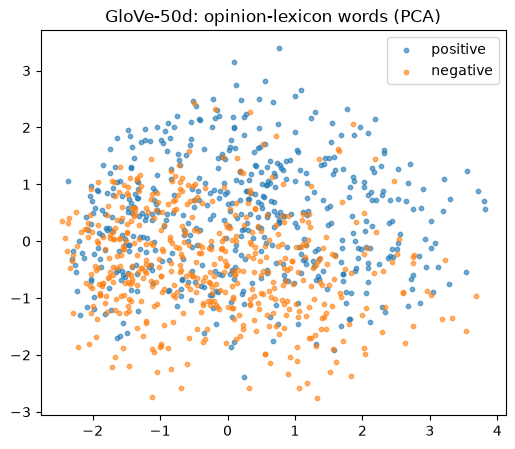

Linear probe, polarity accuracy (5-fold): 0.843 (chance 0.5)


In [13]:
from nltk.corpus import opinion_lexicon
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

pos_lex = set(opinion_lexicon.positive())
neg_lex = set(opinion_lexicon.negative())

lex_rs = np.random.RandomState(0)
pos_words = [w for w in sorted(pos_lex) if w in glove]
neg_words = [w for w in sorted(neg_lex) if w in glove]
pos_words = list(lex_rs.choice(pos_words, min(500, len(pos_words)), replace=False))
neg_words = list(lex_rs.choice(neg_words, min(500, len(neg_words)), replace=False))

X_lex = np.stack([vec(w) for w in pos_words + neg_words])
y_lex = np.array([1] * len(pos_words) + [0] * len(neg_words))

Z = PCA(n_components=2, random_state=0).fit_transform(X_lex)
plt.figure(figsize=(6, 5))
plt.scatter(Z[y_lex == 1, 0], Z[y_lex == 1, 1], s=10, alpha=.6, label='positive')
plt.scatter(Z[y_lex == 0, 0], Z[y_lex == 0, 1], s=10, alpha=.6, label='negative')
plt.legend(); plt.title("GloVe-50d: opinion-lexicon words (PCA)"); plt.show()

# PCA can hide structure; a linear probe tells us whether polarity is linearly decodable
acc = cross_val_score(LogisticRegression(max_iter=2000), X_lex, y_lex, cv=5).mean()
print(f"Linear probe, polarity accuracy (5-fold): {acc:.3f} (chance 0.5)")

### 3.5 Known limitation: antonyms live close together

In [14]:
for a, b in [('good', 'bad'), ('great', 'terrible'), ('love', 'hate'), ('boring', 'exciting'), ('good', 'great'), ('bad', 'awful')]:
    print(f"cos({a}, {b}) = {cos(vec(a), vec(b)):.3f}")
print()
for w in ['good', 'terrible', 'boring', 'amazing', 'waste']:
    print(w, '->', topk_words(vec(w), 10, exclude={w}))

cos(good, bad) = 0.814
cos(great, terrible) = 0.621
cos(love, hate) = 0.630
cos(boring, exciting) = 0.694
cos(good, great) = 0.842
cos(bad, awful) = 0.804

good -> [('better', 0.939), ('really', 0.938), ('always', 0.928), ('something', 0.921), ('kind', 0.92), ('little', 0.919), ('make', 0.919), ('way', 0.917), ('think', 0.916), ('enough', 0.908)]
terrible -> [('horrible', 0.932), ('awful', 0.887), ('dreadful', 0.856), ('tragedy', 0.841), ('horrific', 0.826), ('tragic', 0.82), ('horrendous', 0.817), ('unfortunately', 0.811), ('worse', 0.811), ('mistake', 0.81)]
boring -> [('funny', 0.836), ('awfully', 0.823), ('pretty', 0.809), ('weird', 0.805), ('silly', 0.797), ('bored', 0.79), ('stupid', 0.78), ('incredibly', 0.774), ('stuff', 0.77), ('lazy', 0.77)]
amazing -> [('incredible', 0.942), ('fantastic', 0.898), ('wonderful', 0.873), ('marvelous', 0.873), ('awesome', 0.867), ('terrific', 0.854), ('exciting', 0.841), ('astonishing', 0.841), ('remarkable', 0.832), ('unbelievable', 0.822)]
was

## 4. Task vocabulary and tokenizers

**Task vocabulary.** The full GloVe table has ~1.2M rows, which is wasteful to carry through every model (and to save for every fold). We keep only the GloVe vectors for words that occur in the IMDB texts (train + test texts; no labels are used, so this is only a vocabulary choice and words never seen in training still keep their pretrained GloVe vector). Tokens that GloVe does not know map to `<unk>`.

Special rows: `<pad>` = zeros, `<unk>` = mean GloVe vector.

In [15]:
%%time
all_counts = Counter(token_counts)
for t in test_texts:
    all_counts.update(base_tokens(t))

task_words = ['<pad>', '<unk>'] + sorted(w for w in all_counts if w in glove)
task_vocab = Vocabulary(task_words, default='<unk>')
PAD_ID, UNK_ID = task_vocab.index('<pad>'), task_vocab.default_index

TASK_MATRIX = np.zeros((len(task_vocab), glove.dims), dtype=np.float32)
TASK_MATRIX[UNK_ID] = glove.vectors.mean(0)
for i, w in task_vocab.items():
    if i > UNK_ID:
        TASK_MATRIX[i] = glove.vectors[glove.w2i[w]]
TASK_MATRIX = torch.tensor(TASK_MATRIX)
print("Task vocab:", len(task_vocab), "| matrix:", tuple(TASK_MATRIX.shape), "| PAD, UNK:", PAD_ID, UNK_ID)

Task vocab: 47897 | matrix: (47897, 50) | PAD, UNK: 0 1
CPU times: user 9.53 s, sys: 5.13 s, total: 14.7 s
Wall time: 13.9 s


**Tokenizers.** One class, configured two ways:
- *BoW-style* (embed-and-pool): no punctuation, stopwords removed with a custom list that **keeps negators** (NLTK's list contains `not`, `no`, `nor`, `don`, `couldn`, ...).
- *RNN-style*: keep everything, but truncate to `MAX_LEN_RNN` tokens (`head`, or `headtail` which keeps the first and last N/2 since reviews often give the verdict at the end).

In [16]:
from nltk.corpus import stopwords

NEGATORS = {
    "not", "no", "nor", "never", "n't", "nt", "cannot", "neither", "none", "nothing", "nobody", "nowhere",
    "don", "doesn", "didn", "isn", "aren", "wasn", "weren", "won", "wouldn", "shouldn", "couldn",
    "hasn", "haven", "hadn", "mustn", "needn", "shan", "ain", "mightn",
    "but", "very", "too", "only", "against",     # contrast / intensity words that matter for sentiment
}
STOPWORDS_KEEP_NEG = set(stopwords.words('english')) - NEGATORS
print(len(set(stopwords.words('english'))), "->", len(STOPWORDS_KEEP_NEG), "stopwords after protecting negators")


class ReviewTokenizer:
    """Maps a review to tokens / vocabulary ids. Built on the cached base tokens."""
    def __init__(self, vocab, remove_punct=False, drop_words=None, max_len=None, truncation='head'):
        assert truncation in ('head', 'headtail')
        self.vocab = vocab
        self.remove_punct = remove_punct
        self.drop_words = drop_words or set()
        self.max_len = max_len
        self.truncation = truncation

    def tokens(self, text):
        toks = base_tokens(text)
        if self.remove_punct:
            toks = [t for t in toks if not is_punct(t)]
        if self.drop_words:
            toks = [t for t in toks if t not in self.drop_words]
        toks = list(toks)
        if self.max_len is not None and len(toks) > self.max_len:
            if self.truncation == 'head':
                toks = toks[:self.max_len]
            else:
                half = self.max_len // 2
                toks = toks[:half] + toks[-half:]
        return toks

    def ids(self, text):
        ids = [self.vocab.index(t) for t in self.tokens(text)]
        return ids if ids else [self.vocab.default_index]    # never return an empty sequence


tok_bow = ReviewTokenizer(task_vocab, remove_punct=True, drop_words=STOPWORDS_KEEP_NEG)
tok_bow_all = ReviewTokenizer(task_vocab, remove_punct=True)                      # ablation: keep every stopword
tok_rnn = ReviewTokenizer(task_vocab, max_len=MAX_LEN_RNN, truncation='head')
tok_rnn_ht = ReviewTokenizer(task_vocab, max_len=MAX_LEN_RNN, truncation='headtail')
tok_full = ReviewTokenizer(task_vocab)                                            # no filtering, no truncation (for features)

demo = "This movie wasn't good at all!<br /><br />Great premise, but terrible execution... 3/10."
for name, t in [('bow', tok_bow), ('bow (keep stopwords)', tok_bow_all), ('rnn', tok_rnn)]:
    print(f"{name:22}", t.tokens(demo))

198 -> 171 stopwords after protecting negators
bow                    ['movie', "n't", 'good', 'great', 'premise', 'but', 'terrible', 'execution', '3/10']
bow (keep stopwords)   ['this', 'movie', 'was', "n't", 'good', 'at', 'all', 'great', 'premise', 'but', 'terrible', 'execution', '3/10']
rnn                    ['this', 'movie', 'was', "n't", 'good', 'at', 'all', '!', 'great', 'premise', ',', 'but', 'terrible', 'execution', '...', '3/10', '.']


## 5. Models

### 5.1 Encoders

Both encoders take a padded batch of ids with shape `(batch, max_len)` and return `(batch, enc_dim)`.
- `EmbedAndPoolEncoder`: embeds, then mean (or sum) pools over the *non-pad* positions only.
- `RNNEncoder`: LSTM or GRU, optionally bidirectional, with word dropout (training only: random tokens are replaced by `<unk>`). It uses packed sequences so padding never affects the state, and returns the final state (forward and backward final states concatenated if bidirectional).

In [17]:
class EmbedAndPoolEncoder(nn.Module):
    def __init__(self, embedding_matrix, average_pool=True, padding_idx=0, freeze_embeddings=True):
        super().__init__()
        self.average_pool = average_pool
        self.pad_idx = padding_idx
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=freeze_embeddings, padding_idx=padding_idx)

    @property
    def enc_dim(self):
        return self.embedding.embedding_dim

    def forward(self, x):
        mask = x.ne(self.pad_idx)                                   # (B, L)
        e = self.embedding(x) * mask.unsqueeze(-1)                  # (B, L, D), pads zeroed
        h = e.sum(1)
        if self.average_pool:
            h = h / mask.sum(1, keepdim=True).clamp(min=1)
        return h


class RNNEncoder(nn.Module):
    def __init__(self, hidden_size, embedding_matrix, rnn_type='lstm', bidirectional=False, num_layers=1,
                 padding_idx=0, unk_idx=1, freeze_embeddings=True, word_dropout=0.0, dropout=0.0):
        super().__init__()
        assert rnn_type in ('lstm', 'gru')
        self.rnn_type, self.bidirectional = rnn_type, bidirectional
        self.hidden_size, self.pad_idx, self.unk_idx = hidden_size, padding_idx, unk_idx
        self.word_dropout = word_dropout
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=freeze_embeddings, padding_idx=padding_idx)
        cls = nn.LSTM if rnn_type == 'lstm' else nn.GRU
        self.rnn = cls(embedding_matrix.shape[1], hidden_size, num_layers=num_layers, batch_first=True,
                       bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0.0)

    @property
    def enc_dim(self):
        return self.hidden_size * (2 if self.bidirectional else 1)

    def forward(self, x):
        if self.training and self.word_dropout > 0:
            drop = (torch.rand(x.shape, device=x.device) < self.word_dropout) & x.ne(self.pad_idx)
            x = x.masked_fill(drop, self.unk_idx)
        lengths = x.ne(self.pad_idx).sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.embedding(x), lengths, batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        if self.rnn_type == 'lstm':
            h = h[0]                                                # (layers * dirs, B, H)
        return torch.cat([h[-2], h[-1]], -1) if self.bidirectional else h[-1]

### 5.2 Softmax regressor

MLP on top of the encoding, with `LogSoftmax` output (so the model predicts log-probabilities).

In [18]:
class SoftmaxRegressor(nn.Module):
    def __init__(self, encoder, hidden_size1, hidden_size2, num_classes, dropout=0.1):
        super().__init__()
        self.encoder = encoder
        self.net = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(encoder.enc_dim, hidden_size1), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_size1, hidden_size2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_size2, num_classes),
            nn.LogSoftmax(dim=-1),
        )

    def forward(self, x):
        return self.net(self.encoder(x))


def build_model(cfg):
    """cfg: dict with enc_type in {'embed-and-pool','lstm','bilstm','gru'}, enc_kwargs, regressor_kwargs."""
    matrix = TASK_MATRIX.clone()          # clone: with trainable embeddings we must not modify the shared matrix
    et, kw = cfg['enc_type'], dict(cfg['enc_kwargs'])
    if et == 'embed-and-pool':
        enc = EmbedAndPoolEncoder(matrix, padding_idx=PAD_ID, **kw)
    elif et in ('lstm', 'bilstm', 'gru'):
        enc = RNNEncoder(embedding_matrix=matrix, rnn_type='gru' if et == 'gru' else 'lstm',
                         bidirectional=(et == 'bilstm'), padding_idx=PAD_ID, unk_idx=UNK_ID, **kw)
    else:
        raise ValueError(et)
    return SoftmaxRegressor(enc, num_classes=NUM_CLASSES, **cfg['regressor_kwargs'])

### 5.3 Training, prediction, saving and loading

In [19]:
def collate(id_lists):
    return pad_sequence([torch.tensor(s, dtype=torch.long) for s in id_lists], batch_first=True, padding_value=PAD_ID)


@torch.no_grad()
def predict_ids(model, id_lists, batch_size=64, device='cpu'):
    """Log-probs for tokenized inputs. Sorts by length for speed, returns in the original order."""
    model.eval().to(device)
    order = np.argsort([len(s) for s in id_lists])
    out = np.zeros((len(id_lists), NUM_CLASSES), dtype=np.float32)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        out[idx] = model(collate([id_lists[i] for i in idx]).to(device)).cpu().numpy()
    return out


def predict_logprobs(model, tokenizer, texts, batch_size=64, device='cpu'):
    return predict_ids(model, [tokenizer.ids(t) for t in texts], batch_size, device)


def evaluate(model, id_lists, labels, batch_size=64, device='cpu'):
    lp = predict_ids(model, id_lists, batch_size, device)
    y = np.asarray(labels)
    return float(-lp[np.arange(len(y)), y].mean()), float((lp.argmax(-1) == y).mean())


def train(train_pairs, val_pairs, tokenizer, cfg, opt_kwargs, device, save_to, seed=0, verbose=True):
    """
    Trains one model, keeps the epoch with the lowest validation loss, saves it to save_to/model.pt.
    Returns (metrics per epoch, best epoch index).
    """
    o = {'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 64, 'num_epochs': NUM_EPOCHS}
    o.update(opt_kwargs or {})
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)

    tr_ids, tr_y = [tokenizer.ids(t) for t, _ in train_pairs], np.array([l for _, l in train_pairs])
    va_ids, va_y = [tokenizer.ids(t) for t, _ in val_pairs], np.array([l for _, l in val_pairs])

    model = build_model(cfg).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                           lr=o['learning_rate'], weight_decay=o['weight_decay'])
    loss_fn = nn.NLLLoss()

    metrics, best_epoch, best_state, best_val = [], 0, None, float('inf')
    for epoch in range(o['num_epochs']):
        model.train()
        perm = rng.permutation(len(tr_ids))
        total, correct = 0.0, 0
        for start in range(0, len(perm), o['batch_size']):
            idx = perm[start:start + o['batch_size']]
            xb = collate([tr_ids[i] for i in idx]).to(device)
            yb = torch.tensor(tr_y[idx], dtype=torch.long, device=device)
            opt.zero_grad()
            lp = model(xb)
            loss = loss_fn(lp, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item() * len(idx)
            correct += (lp.argmax(-1) == yb).sum().item()
        val_loss, val_acc = evaluate(model, va_ids, va_y, device=device)
        metrics.append({'epoch': epoch, 'train_loss': total / len(perm), 'train_acc': correct / len(perm),
                        'val_loss': val_loss, 'val_acc': val_acc})
        if verbose:
            m = metrics[-1]
            print(f"epoch {epoch:2d} | train loss {m['train_loss']:.4f} acc {m['train_acc']:.4f} | "
                  f"val loss {m['val_loss']:.4f} acc {m['val_acc']:.4f}")
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    # frozen embeddings are identical to TASK_MATRIX, so we do not store them (saves a lot of disk)
    if cfg['enc_kwargs'].get('freeze_embeddings', True):
        best_state = {k: v for k, v in best_state.items() if 'embedding.weight' not in k}
    Path(save_to).mkdir(parents=True, exist_ok=True)
    torch.save({'cfg': cfg, 'state': best_state, 'best_epoch': best_epoch}, Path(save_to) / "model.pt")
    return metrics, best_epoch


def load_model(save_to):
    ckpt = torch.load(Path(save_to) / "model.pt", map_location='cpu')
    model = build_model(ckpt['cfg'])
    missing, unexpected = model.load_state_dict(ckpt['state'], strict=False)
    assert not unexpected and all('embedding.weight' in k for k in missing), (missing, unexpected)
    return model.eval()

### 5.4 Data splits

Stratified k-fold on the training set (our cross-validation), and a stratified split of the test set into `devtest` (for analysis) and `test` (unseen).

In [20]:
def cross_validation_split(pairs, k, seed):
    labels = [l for _, l in pairs]
    folds = []
    for tr, va in StratifiedKFold(n_splits=k, shuffle=True, random_state=seed).split(np.zeros(len(labels)), labels):
        folds.append({'training': [pairs[i] for i in tr], 'validation': [pairs[i] for i in va]})
    return folds


def split_test_devtest(texts, labels, devtest_size, seed):
    dev_idx, test_idx = train_test_split(np.arange(len(texts)), train_size=devtest_size, stratify=labels, random_state=seed)
    return {
        'devtest': [(texts[i], labels[i]) for i in dev_idx], 'devtest_ids': [int(i) for i in dev_idx],
        'test': [(texts[i], labels[i]) for i in test_idx], 'test_ids': [int(i) for i in test_idx],
    }


train_pairs = list(zip(train_texts, train_labels))
my_cross_validation_sets = [cross_validation_split(train_pairs, NUM_FOLDS, s) for s in SEEDS]
my_test_sets = [split_test_devtest(test_texts, test_labels, DEVTEST_SIZE, s) for s in SEEDS]
print(len(my_cross_validation_sets[0][0]['training']), "train /", len(my_cross_validation_sets[0][0]['validation']), "val per fold")
print(len(my_test_sets[0]['devtest']), "devtest /", len(my_test_sets[0]['test']), "test")

2666 train / 1334 val per fold
1000 devtest / 4000 test


## 6. Experiments

### 6.1 Sanity check: one training run per encoder

Watch `val loss`: if it rises while `train loss` keeps falling, the model is overfitting (more dropout / word dropout / weight decay, smaller hidden size).

In [21]:
cfg_pool = {'enc_type': 'embed-and-pool', 'enc_kwargs': {'freeze_embeddings': True},
            'regressor_kwargs': {'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.5}}
fold0 = my_cross_validation_sets[0][0]
metrics, best_epoch = train(fold0['training'], fold0['validation'], tok_bow, cfg_pool,
                            {}, DEVICE, results_folder / "tmp-pool")
print("best epoch:", best_epoch, "| val acc:", metrics[best_epoch]['val_acc'])

epoch  0 | train loss 0.6954 acc 0.5068 | val loss 0.6898 acc 0.5075
epoch  1 | train loss 0.6889 acc 0.5386 | val loss 0.6848 acc 0.6357
epoch  2 | train loss 0.6873 acc 0.5514 | val loss 0.6764 acc 0.6349
best epoch: 2 | val acc: 0.6349325337331334


In [22]:
cfg_lstm = {'enc_type': 'lstm', 'enc_kwargs': {'freeze_embeddings': True, 'hidden_size': 64, 'word_dropout': 0.1},
            'regressor_kwargs': {'hidden_size1': 50, 'hidden_size2': 50, 'dropout': 0.1}}
metrics, best_epoch = train(fold0['training'], fold0['validation'], tok_rnn, cfg_lstm,
                            {'batch_size': 32}, DEVICE, results_folder / "tmp-lstm")
print("best epoch:", best_epoch, "| val acc:", metrics[best_epoch]['val_acc'])

epoch  0 | train loss 0.6939 acc 0.5150 | val loss 0.6903 acc 0.5510
epoch  1 | train loss 0.6841 acc 0.5713 | val loss 0.6676 acc 0.6319
epoch  2 | train loss 0.6509 acc 0.6365 | val loss 0.6348 acc 0.6529
best epoch: 2 | val acc: 0.6529235382308846


### 6.2 Cross validation

`run_cv` runs every seed x fold for one configuration and records the best-epoch validation metrics. The tokenizer and config of each system are stored by name; the analysis section reuses them.

In [23]:
cv_rows = []
system_tokenizer = OrderedDict()
system_cfg = OrderedDict()

def run_cv(name, tokenizer, cfg, opt_kwargs=None):
    system_tokenizer[name], system_cfg[name] = tokenizer, cfg
    for run, seed in enumerate(SEEDS):
        for fold, split in enumerate(my_cross_validation_sets[run]):
            metrics, best = train(split['training'], split['validation'], tokenizer, cfg, opt_kwargs, DEVICE,
                                  f"{results_folder}/{name}/seed-{seed}/fold-{fold}", seed=seed, verbose=False)
            cv_rows.append({'system': name, 'seed': seed, 'run': run, 'fold': fold, 'best_epoch': best,
                            'val_acc': metrics[best]['val_acc'], 'val_loss': metrics[best]['val_loss']})
            print(f"{name} | seed {seed} fold {fold} | best epoch {best} | val acc {metrics[best]['val_acc']:.4f}")

**Embed-and-pool** (stopword ablation and fine-tuned embeddings):

In [24]:
%%time
run_cv('embed-and-pool', tok_bow, cfg_pool)

embed-and-pool | seed 0 fold 0 | best epoch 2 | val acc 0.6349
embed-and-pool | seed 0 fold 1 | best epoch 2 | val acc 0.6182
embed-and-pool | seed 0 fold 2 | best epoch 2 | val acc 0.6534
CPU times: user 7.22 s, sys: 95 ms, total: 7.31 s
Wall time: 2.42 s


In [25]:
%%time
run_cv('embed-and-pool (keep stopwords)', tok_bow_all, cfg_pool)

embed-and-pool (keep stopwords) | seed 0 fold 0 | best epoch 2 | val acc 0.5180
embed-and-pool (keep stopwords) | seed 0 fold 1 | best epoch 2 | val acc 0.6122
embed-and-pool (keep stopwords) | seed 0 fold 2 | best epoch 2 | val acc 0.6227
CPU times: user 12.9 s, sys: 108 ms, total: 13 s
Wall time: 2.82 s


In [26]:
%%time
run_cv('embed-and-pool (finetuned)', tok_bow,
       {**cfg_pool, 'enc_kwargs': {'freeze_embeddings': False}})

embed-and-pool (finetuned) | seed 0 fold 0 | best epoch 2 | val acc 0.6274
embed-and-pool (finetuned) | seed 0 fold 1 | best epoch 2 | val acc 0.6107
embed-and-pool (finetuned) | seed 0 fold 2 | best epoch 2 | val acc 0.6512
CPU times: user 7.69 s, sys: 229 ms, total: 7.92 s
Wall time: 2.75 s


**Recurrent encoders** (head vs head+tail truncation, unidirectional vs bidirectional, GRU):

In [27]:
%%time
run_cv('lstm', tok_rnn, cfg_lstm, {'batch_size': 32})

lstm | seed 0 fold 0 | best epoch 2 | val acc 0.6529
lstm | seed 0 fold 1 | best epoch 1 | val acc 0.6392
lstm | seed 0 fold 2 | best epoch 2 | val acc 0.6527
CPU times: user 7.54 s, sys: 256 ms, total: 7.79 s
Wall time: 7.3 s


In [28]:
%%time
run_cv('lstm (head+tail)', tok_rnn_ht, cfg_lstm, {'batch_size': 32})

lstm (head+tail) | seed 0 fold 0 | best epoch 2 | val acc 0.5840
lstm (head+tail) | seed 0 fold 1 | best epoch 2 | val acc 0.6639
lstm (head+tail) | seed 0 fold 2 | best epoch 2 | val acc 0.6887
CPU times: user 7.41 s, sys: 235 ms, total: 7.64 s
Wall time: 7.15 s


In [29]:
%%time
run_cv('bilstm', tok_rnn, {**cfg_lstm, 'enc_type': 'bilstm'}, {'batch_size': 32})

bilstm | seed 0 fold 0 | best epoch 1 | val acc 0.6057
bilstm | seed 0 fold 1 | best epoch 1 | val acc 0.6617
bilstm | seed 0 fold 2 | best epoch 2 | val acc 0.6474
CPU times: user 11.6 s, sys: 239 ms, total: 11.9 s
Wall time: 11.4 s


In [30]:
%%time
run_cv('gru', tok_rnn, {**cfg_lstm, 'enc_type': 'gru'}, {'batch_size': 32})

gru | seed 0 fold 0 | best epoch 2 | val acc 0.7174
gru | seed 0 fold 1 | best epoch 2 | val acc 0.6369
gru | seed 0 fold 2 | best epoch 1 | val acc 0.5881
CPU times: user 8.02 s, sys: 233 ms, total: 8.25 s
Wall time: 7.79 s


### 6.3 Compare systems (keep the spread, not just the mean)

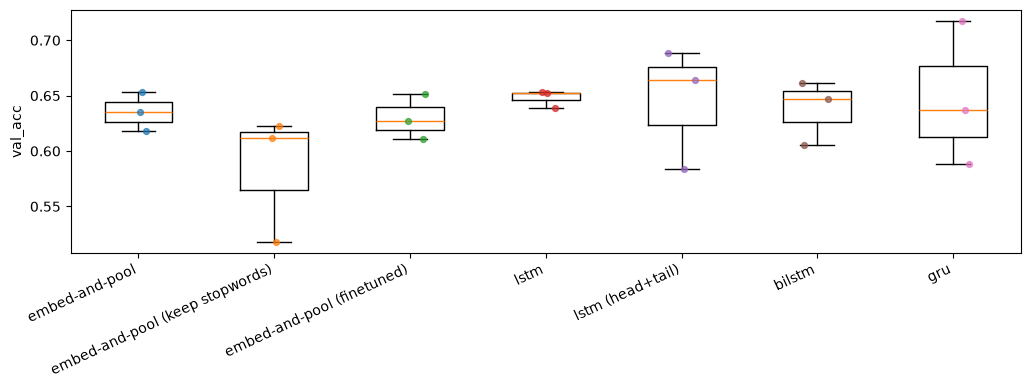

,mean,std,min,max,count
system,,,,,
bilstm,0.6383,0.0291,0.6057,0.6617,3
embed-and-pool,0.6355,0.0176,0.6182,0.6534,3
embed-and-pool (finetuned),0.6298,0.0204,0.6107,0.6512,3
embed-and-pool (keep stopwords),0.5843,0.0576,0.5180,0.6227,3
gru,0.6475,0.0653,0.5881,0.7174,3
lstm,0.6482,0.0079,0.6392,0.6529,3
lstm (head+tail),0.6455,0.0547,0.5840,0.6887,3


In [31]:
cv_df = pd.DataFrame(cv_rows)

def plot_box_and_points(df, value='val_acc'):
    systems = list(dict.fromkeys(df['system']))
    data = [df.loc[df['system'] == s, value].to_numpy() for s in systems]
    fig, ax = plt.subplots(figsize=(max(6, 1.5 * len(systems)), 4))
    ax.boxplot(data, showfliers=False)
    jitter = np.random.RandomState(0)
    for i, d in enumerate(data, 1):
        ax.scatter(i + jitter.uniform(-0.12, 0.12, len(d)), d, s=18, alpha=0.7, zorder=3)
    ax.set_xticks(range(1, len(systems) + 1))
    ax.set_xticklabels(systems, rotation=25, ha='right')
    ax.set_ylabel(value)
    plt.tight_layout()
    plt.show()

plot_box_and_points(cv_df)
cv_df.groupby('system')['val_acc'].agg(['mean', 'std', 'min', 'max', 'count']).round(4)

## 7. Data-size study

Does the recurrent encoder (and pretraining) need more data? Train on increasing subsets of fold 0's training portion and evaluate on its validation portion (one seed, to keep it cheap).

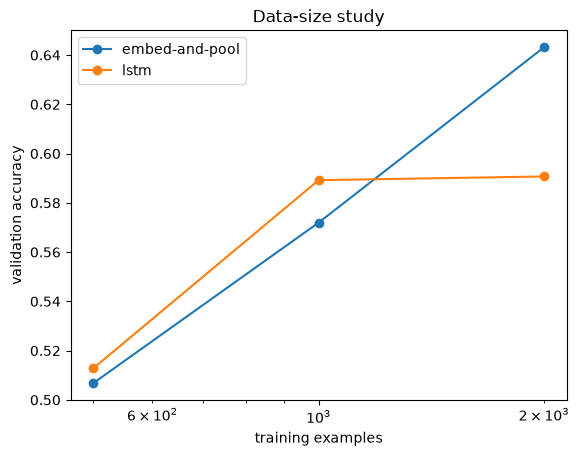

CPU times: user 8.27 s, sys: 194 ms, total: 8.47 s
Wall time: 5.5 s


,n_train,system,val_acc
0,500,embed-and-pool,0.506747
1,500,lstm,0.512744
2,1000,embed-and-pool,0.571964
3,1000,lstm,0.589205
4,2000,embed-and-pool,0.643178
5,2000,lstm,0.590705


In [32]:
%%time
sizes = [500, 1000, 2000] if FAST_DEV else [1000, 5000, 25000]
sub_rs = np.random.RandomState(0)
fold0_train = [fold0['training'][i] for i in sub_rs.permutation(len(fold0['training']))]
size_rows = []
for n in sizes:
    n = min(n, len(fold0_train))
    for name, tok, cfg, opt in [('embed-and-pool', tok_bow, cfg_pool, {}), ('lstm', tok_rnn, cfg_lstm, {'batch_size': 32})]:
        m, best = train(fold0_train[:n], fold0['validation'], tok, cfg, opt, DEVICE,
                        results_folder / f"size-{n}-{name}", verbose=False)
        size_rows.append({'n_train': n, 'system': name, 'val_acc': m[best]['val_acc']})
size_df = pd.DataFrame(size_rows)
for name, g in size_df.groupby('system'):
    plt.plot(g['n_train'], g['val_acc'], marker='o', label=name)
plt.xscale('log'); plt.xlabel('training examples'); plt.ylabel('validation accuracy'); plt.legend()
plt.title("Data-size study"); plt.show()
size_df

## 8. Error analysis

### 8.1 Features of each devtest review

Computed from the untruncated tokens, so every system sees the same feature values.

In [35]:
import textstat

NEGATION_TOKENS = {"not", "no", "never", "n't", "nt", "nothing", "nobody", "none", "neither", "nor", "cannot", "nowhere"}
CONTRAST_TOKENS = {"but", "however", "although", "though", "yet", "despite", "nevertheless", "whereas"}

def featurize(text):
    toks = base_tokens(text)
    n = max(len(toks), 1)
    n_pos = sum(t in pos_lex for t in toks)
    n_neg = sum(t in neg_lex for t in toks)
    return {
        'length': len(toks),
        'oov_rate': sum(t not in glove for t in toks) / n,
        'negations': sum(t in NEGATION_TOKENS for t in toks),
        'lex_pos': n_pos,
        'lex_neg': n_neg,
        'lex_mixed': min(n_pos, n_neg),          # mixed reviews should be hard
        'lex_balance': (n_pos - n_neg) / n,      # net polarity density
        'contrast': sum(t in CONTRAST_TOKENS for t in toks),
        'exclaim': sum(t == '!' for t in toks),
        'question': sum(t == '?' for t in toks),
        'flesch_reading_ease': textstat.flesch_reading_ease(clean_text(text)),
    }

feature_cols = ['length', 'oov_rate', 'negations', 'lex_pos', 'lex_neg', 'lex_mixed', 'lex_balance',
                'contrast', 'exclaim', 'question', 'flesch_reading_ease']
devtest_feats = [pd.DataFrame([featurize(t) for t, _ in ts['devtest']]) for ts in my_test_sets]
devtest_feats[0].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
length,1000.0,268.429,203.246,22.000,144.750,197.000,318.250,1185.000
oov_rate,1000.0,0.009,0.011,0.000,0.000,0.006,0.013,0.081
negations,1000.0,3.720,3.579,0.000,1.000,3.000,5.000,23.000
lex_pos,1000.0,9.754,7.829,0.000,5.000,8.000,12.000,51.000
lex_neg,1000.0,9.468,8.496,0.000,4.000,7.000,13.000,67.000
lex_mixed,1000.0,6.817,6.241,0.000,3.000,5.000,9.000,45.000
lex_balance,1000.0,0.003,0.033,-0.156,-0.017,0.002,0.023,0.138
contrast,1000.0,2.267,2.442,0.000,1.000,2.000,3.000,22.000
exclaim,1000.0,1.028,2.783,0.000,0.000,0.000,1.000,61.000
question,1000.0,0.696,1.567,0.000,0.000,0.000,1.000,18.000


### 8.2 Predictions of every trained fold on the devtest set

In [36]:
%%time
rows, systems, items = [], {}, {}
for name in system_cfg:
    sid = systems.setdefault(name, len(systems))
    for run, seed in enumerate(SEEDS):
        dev = my_test_sets[run]['devtest']
        texts = [t for t, _ in dev]
        labels = np.array([l for _, l in dev], dtype=int)
        feats = devtest_feats[run]
        for fold in range(NUM_FOLDS):
            model = load_model(f"{results_folder}/{name}/seed-{seed}/fold-{fold}")
            logprobs = predict_logprobs(model, system_tokenizer[name], texts, 64, DEVICE)
            preds = logprobs.argmax(-1)
            conf = np.exp(logprobs.max(-1))
            for i in range(len(preds)):
                item_id = items.setdefault((run, my_test_sets[run]['devtest_ids'][i]), len(items))
                rows.append({'system': name, 'system_id': sid, 'item_id': item_id, 'run': run, 'fold': fold,
                             'label': labels[i], 'pred': preds[i], 'correct': int(labels[i] == preds[i]),
                             'confidence': conf[i], **feats.iloc[i].to_dict()})
df = pd.DataFrame(rows)
print(df.shape)
print(df.groupby('system')['correct'].mean().round(4))

(21000, 20)
system
bilstm                             0.6380
embed-and-pool                     0.6500
embed-and-pool (finetuned)         0.6433
embed-and-pool (keep stopwords)    0.5810
gru                                0.6380
lstm                               0.6390
lstm (head+tail)                   0.6363
Name: correct, dtype: float64
CPU times: user 4.2 s, sys: 157 ms, total: 4.35 s
Wall time: 3.25 s


In [37]:
for name in system_cfg:
    sub = df[(df['system'] == name) & (df['run'] == 0) & (df['fold'] == 0)]
    print(name)
    print(classification_report(sub['label'], sub['pred'], target_names=CLASS_NAMES, digits=3))

embed-and-pool
              precision    recall  f1-score   support

    negative      0.824     0.364     0.505       500
    positive      0.592     0.922     0.721       500

    accuracy                          0.643      1000
   macro avg      0.708     0.643     0.613      1000
weighted avg      0.708     0.643     0.613      1000

embed-and-pool (keep stopwords)
              precision    recall  f1-score   support

    negative      0.769     0.020     0.039       500
    positive      0.504     0.994     0.668       500

    accuracy                          0.507      1000
   macro avg      0.636     0.507     0.354      1000
weighted avg      0.636     0.507     0.354      1000

embed-and-pool (finetuned)
              precision    recall  f1-score   support

    negative      0.848     0.324     0.469       500
    positive      0.582     0.942     0.720       500

    accuracy                          0.633      1000
   macro avg      0.715     0.633     0.594      1000


### 8.3 Bayesian model of correctness

Observables: correctness $c_n$, system id $s_n$, feature vector $\mathbf f_n$. Latents (all Laplace(0, 1) priors, which encourage zero weights): global logit $\phi$, system shifts $\delta_s$, per-system feature weights $\mathbf w_s$.

$$c_n \sim \operatorname{Bernoulli}(\operatorname{sigmoid}(\phi + \delta_{s_n} + \mathbf w_{s_n}^\top \mathbf f_n))$$

Features are standardised before fitting, so weights are comparable. We also record each system's accuracy as a derived quantity. Inference uses NUTS (MCMC) from numpyro.

In [38]:
import jax
import jax.numpy as jnp
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS


def one_hot(a, k):
    return np.eye(k)[np.asarray(a, dtype=int)]


def bda_model(sys_id, features, num_systems, correctness=None):
    n, f = features.shape
    phi = numpyro.sample('phi', dist.Laplace(0., 1.))
    sys_shift = numpyro.sample('sys_shift', dist.Laplace(jnp.zeros(num_systems), 1.).to_event(1))
    w = numpyro.sample('w', dist.Laplace(jnp.zeros((num_systems, f)), 1.).to_event(2))
    mu = phi + sys_shift[sys_id] + jnp.sum(w[sys_id] * features, axis=-1)
    with numpyro.plate('obs_plate', n):
        numpyro.sample('obs', dist.Bernoulli(logits=mu), obs=correctness)
    membership = jax.nn.one_hot(sys_id, num_systems)
    numpyro.deterministic('accuracy', (membership * jax.nn.sigmoid(mu)[:, None]).sum(0) / membership.sum(0))


def fit_bda_model(num_systems, sys_id, features, correctness, num_chains=2, num_warmup=500, num_samples=500, seed=0):
    features = np.asarray(features, dtype=np.float32)
    std = features.std(0)
    features = (features - features.mean(0)) / np.where(std > 0, std, 1.0)      # standardise
    mcmc = MCMC(NUTS(bda_model), num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, progress_bar=True)
    mcmc.run(jax.random.PRNGKey(seed), sys_id=jnp.asarray(sys_id, dtype=jnp.int32), features=jnp.asarray(features),
             num_systems=num_systems, correctness=jnp.asarray(correctness, dtype=jnp.int32))
    return mcmc

In [39]:
%%time
df_model = df.copy()
df_model['length'] = np.log1p(df_model['length'])      # tame the heavy right tail of review length

mcmc = fit_bda_model(
    num_systems=len(systems),
    sys_id=df_model['system_id'].to_numpy(),
    features=np.hstack([
        one_hot(df_model['pred'].to_numpy(), NUM_CLASSES),          # which class the system predicted
        df_model[feature_cols].to_numpy(dtype=float),
    ]),
    correctness=df_model['correct'].to_numpy(),
    num_chains=2,
)
mcmc.print_summary(exclude_deterministic=True)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]


                  mean       std    median      5.0%     95.0%     n_eff     r_hat
         phi      0.53      0.21      0.56      0.14      0.80    183.53      1.00
sys_shift[0]      0.15      0.21      0.12     -0.14      0.50    188.05      1.00
sys_shift[1]     -0.16      0.21     -0.18     -0.45      0.20    184.58      1.00
sys_shift[2]      0.12      0.21      0.09     -0.20      0.46    186.07      1.00
sys_shift[3]      0.05      0.21      0.02     -0.24      0.42    185.39      1.00
sys_shift[4]      0.08      0.21      0.06     -0.26      0.40    187.21      1.00
sys_shift[5]      0.05      0.21      0.03     -0.26      0.40    195.62      1.00
sys_shift[6]      0.07      0.21      0.05     -0.21      0.45    185.38      1.00
      w[0,0]     -0.10      0.67     -0.09     -1.41      0.75    573.62      1.00
      w[0,1]      0.06      0.67      0.06     -1.21      0.93    559.87      1.00
      w[0,2]     -0.18      0.08     -0.17     -0.30     -0.04   1197.31      1.00
   

Convergence check: `r_hat` should be ~1.0 and there should be (almost) no divergences.

In [40]:
samples = mcmc.get_samples()
print("Weight samples:", samples['w'].shape)
print("Divergences:", int(mcmc.get_extra_fields()['diverging'].sum()))

Weight samples: (1000, 7, 13)
Divergences: 0


In [41]:
import arviz as az

system_names = [n for n, _ in sorted(systems.items(), key=lambda p: p[1])]
feature_names = [f"pred:{n}" for n in CLASS_NAMES] + feature_cols

posterior_data = az.from_numpyro(
    mcmc,
    coords={'system': system_names, 'feature': feature_names},
    dims={'sys_shift': ['system'], 'w': ['system', 'feature'], 'accuracy': ['system']},
    log_likelihood=False,
)
az_stats_params = {'point_estimate': 'median', 'ci_kind': 'hdi', 'ci_probs': (0.5, 0.95)}

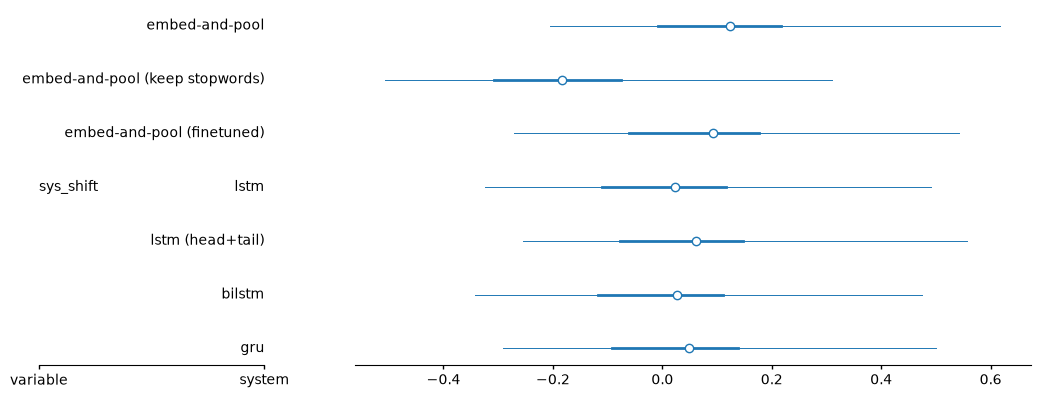

In [42]:
az.plot_forest(posterior_data, var_names=['sys_shift'], combined=True, **az_stats_params)

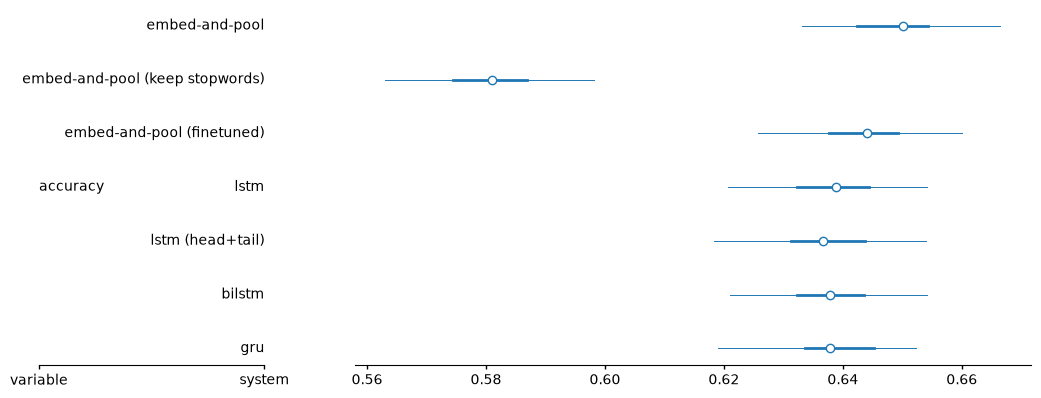

In [43]:
az.plot_forest(posterior_data, var_names=['accuracy'], combined=True, **az_stats_params)

Feature weights per system (standardised features). Below 0: the system does worse as the feature grows; above 0: better; near 0: the feature does not explain that system's correctness.

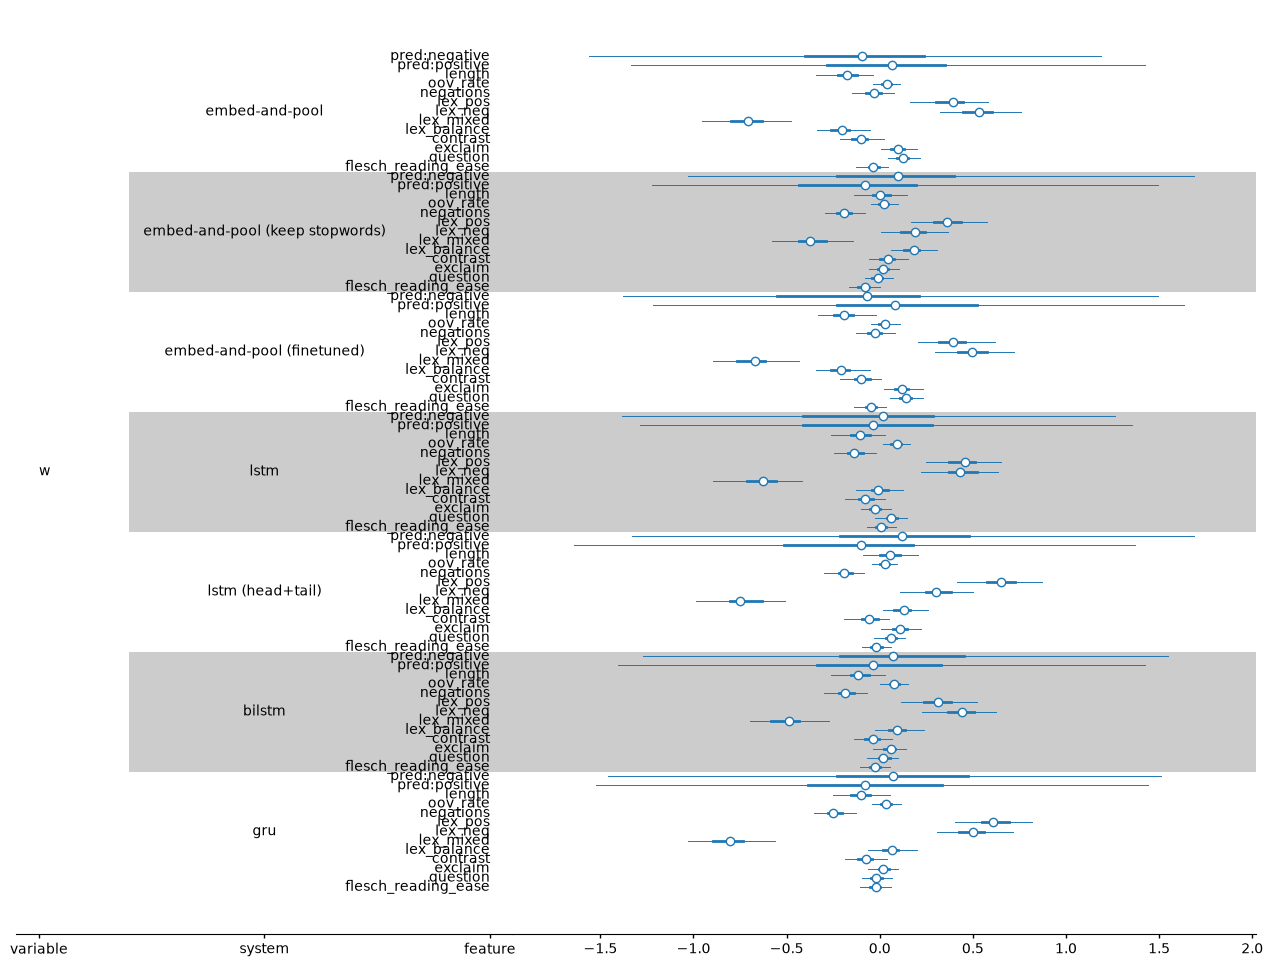

In [46]:
az.plot_forest(
    posterior_data, var_names=['w'], combined=True, shade_label="system",
    figure_kwargs={"figsize": (16, 12), "width_ratios": [2, 3], "layout": "none"},
    **az_stats_params,
)

Same weights grouped by feature, so systems sit side by side:

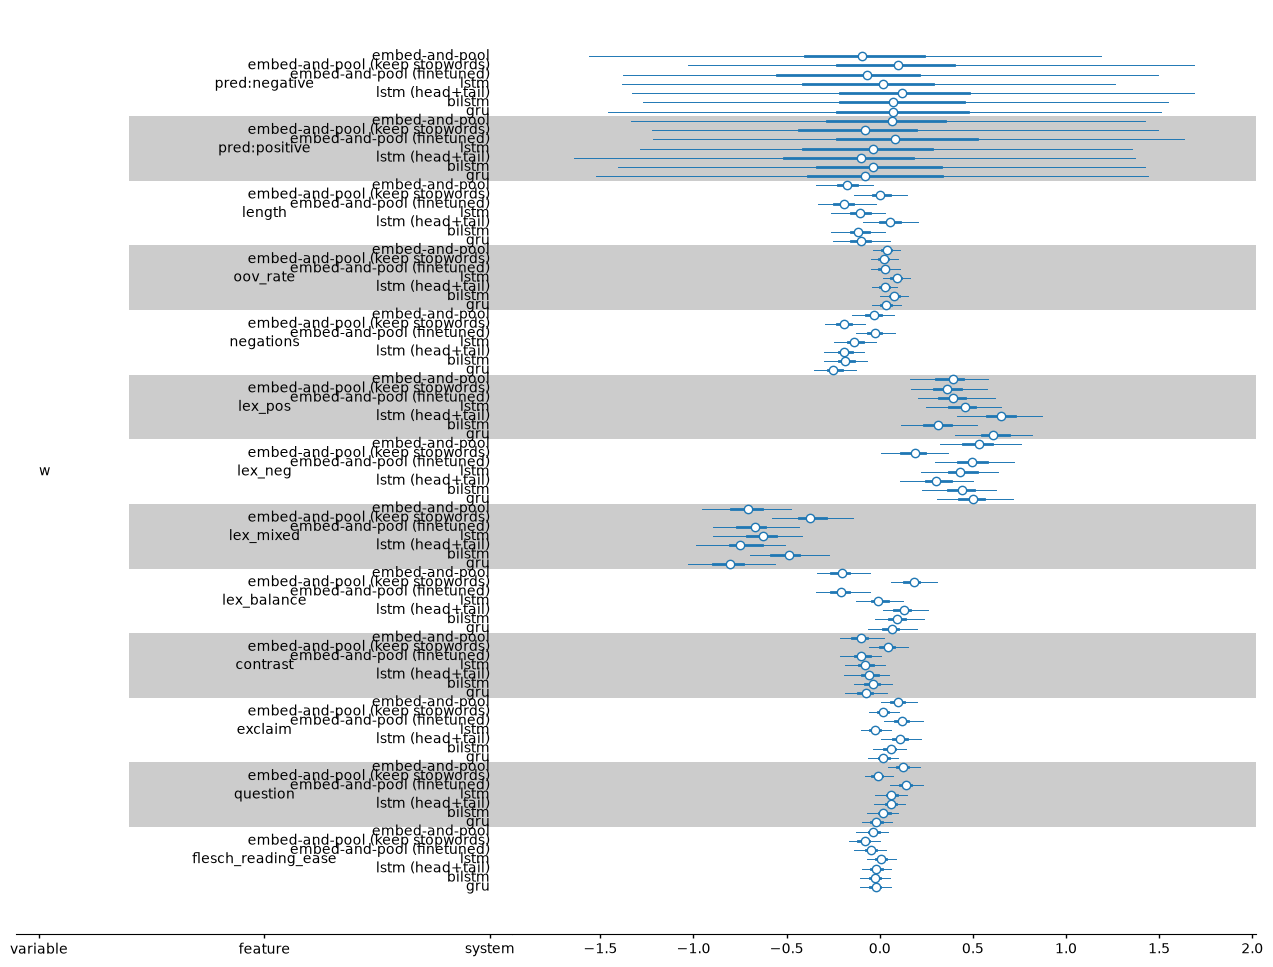

In [47]:
plot_data = posterior_data.copy()
plot_data["posterior"] = posterior_data.posterior["w"].transpose("chain", "draw", "feature", "system").to_dataset()
az.plot_forest(
    plot_data, var_names=["w"], combined=True, shade_label="feature",
    figure_kwargs={"figsize": (16, 12), "width_ratios": [2, 3], "layout": "none"},
    **az_stats_params,
)

### 8.4 Read actual errors

The statistics tell you where to look; the examples tell you why.

In [48]:
fold_df = df[(df['run'] == 0) & (df['fold'] == 0)]
wide = fold_df.pivot(index='item_id', columns='system', values='correct')
item_text = {items[(0, i)]: t for i, (t, _) in zip(my_test_sets[0]['devtest_ids'], my_test_sets[0]['devtest'])}

if {'embed-and-pool', 'lstm'} <= set(wide.columns):
    lstm_only = wide[(wide['lstm'] == 1) & (wide['embed-and-pool'] == 0)].index[:3]
    pool_only = wide[(wide['lstm'] == 0) & (wide['embed-and-pool'] == 1)].index[:3]
    print("=== LSTM right, embed-and-pool wrong ===")
    for it in lstm_only:
        print(clean_text(item_text[it])[:500], "\n---")
    print("=== embed-and-pool right, LSTM wrong ===")
    for it in pool_only:
        print(clean_text(item_text[it])[:500], "\n---")

=== LSTM right, embed-and-pool wrong ===
While it was nice to see a film about older people finding each other and falling in love and the performances by Andrews and Garner were not bad, this picture poured on the sapp and schmaltz at every turn. Every curve in the plot was in view from a mile away! 
---
This mess starts off with a real tank running over a car, intercut with images of a toy tank. This is followed by a family driving home from a birthday party without saying anything. The unexplained tank and the untalkative family take up, I swear, over 10 minutes of film. Finally, the family sees a car after it has been in a wreck and decides to report it to the proper authorities, only to find that the citizens of the town are all hiding in their houses, and the cops are hiding in the police s 
---
I usually like hongkong - martial arts - fantasy movies but I hated this one. Once Upon A Time In China, Shogun Assassin, A Chinese Ghost Story and even Big Trouble In Little China are my